In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import pearsonr, spearmanr

In [2]:
url = "https://raw.githubusercontent.com/NidhiU-24/Student-Mental-Health-Assessment/main/students_mental_health_survey.csv"
df = pd.read_csv(url)
df.head()

,Age,Course,Gender,CGPA,Stress_Level,Depression_Score,Anxiety_Score,Sleep_Quality,Physical_Activity,Diet_Quality,Social_Support,Relationship_Status,Substance_Use,Counseling_Service_Use,Family_History,Chronic_Illness,Financial_Stress,Extracurricular_Involvement,Semester_Credit_Load,Residence_Type
0,25,Others,Male,3.56,3,3,2,Good,Moderate,Good,Moderate,Married,Never,Never,No,No,2,Moderate,17,On-Campus
1,24,Engineering,Female,2.44,0,3,0,Average,Low,Average,Low,Single,Occasionally,Occasionally,No,No,3,Low,27,On-Campus
2,19,Business,Female,3.74,4,0,3,Good,Low,Average,Moderate,In a Relationship,Never,Occasionally,No,No,4,High,15,On-Campus
3,19,Computer Science,Male,3.65,2,1,0,Average,Low,Average,Moderate,Single,NaN,Never,No,No,4,Moderate,20,Off-Campus
4,18,Business,Male,3.40,3,3,4,Good,Low,Average,High,Married,Never,Never,No,Yes,0,High,23,On-Campus


In [3]:
df_clean = df.copy()
df_clean.head()

,Age,Course,Gender,CGPA,Stress_Level,Depression_Score,Anxiety_Score,Sleep_Quality,Physical_Activity,Diet_Quality,Social_Support,Relationship_Status,Substance_Use,Counseling_Service_Use,Family_History,Chronic_Illness,Financial_Stress,Extracurricular_Involvement,Semester_Credit_Load,Residence_Type
0,25,Others,Male,3.56,3,3,2,Good,Moderate,Good,Moderate,Married,Never,Never,No,No,2,Moderate,17,On-Campus
1,24,Engineering,Female,2.44,0,3,0,Average,Low,Average,Low,Single,Occasionally,Occasionally,No,No,3,Low,27,On-Campus
2,19,Business,Female,3.74,4,0,3,Good,Low,Average,Moderate,In a Relationship,Never,Occasionally,No,No,4,High,15,On-Campus
3,19,Computer Science,Male,3.65,2,1,0,Average,Low,Average,Moderate,Single,NaN,Never,No,No,4,Moderate,20,Off-Campus
4,18,Business,Male,3.40,3,3,4,Good,Low,Average,High,Married,Never,Never,No,Yes,0,High,23,On-Campus


In [4]:
df_clean.drop_duplicates(inplace= True)

In [5]:
df_clean.dropna(inplace= True)

In [6]:
df_clean.columns

Index(['Age', 'Course', 'Gender', 'CGPA', 'Stress_Level', 'Depression_Score',
       'Anxiety_Score', 'Sleep_Quality', 'Physical_Activity', 'Diet_Quality',
       'Social_Support', 'Relationship_Status', 'Substance_Use',
       'Counseling_Service_Use', 'Family_History', 'Chronic_Illness',
       'Financial_Stress', 'Extracurricular_Involvement',
       'Semester_Credit_Load', 'Residence_Type'],
      dtype='object')

In [7]:
df_clean['Gender'] = df_clean['Gender'].map({'Male' : 0, 'Female' : 1})
df_clean.rename(columns= {'Gender' : 'Female'}, inplace= True)
df_clean.head()

,Age,Course,Female,CGPA,Stress_Level,Depression_Score,Anxiety_Score,Sleep_Quality,Physical_Activity,Diet_Quality,Social_Support,Relationship_Status,Substance_Use,Counseling_Service_Use,Family_History,Chronic_Illness,Financial_Stress,Extracurricular_Involvement,Semester_Credit_Load,Residence_Type
0,25,Others,0,3.56,3,3,2,Good,Moderate,Good,Moderate,Married,Never,Never,No,No,2,Moderate,17,On-Campus
1,24,Engineering,1,2.44,0,3,0,Average,Low,Average,Low,Single,Occasionally,Occasionally,No,No,3,Low,27,On-Campus
2,19,Business,1,3.74,4,0,3,Good,Low,Average,Moderate,In a Relationship,Never,Occasionally,No,No,4,High,15,On-Campus
4,18,Business,0,3.40,3,3,4,Good,Low,Average,High,Married,Never,Never,No,Yes,0,High,23,On-Campus
5,21,Medical,1,3.35,2,4,3,Good,Moderate,Good,High,Single,Never,Never,No,No,5,Moderate,19,Off-Campus


In [8]:
df_clean['Sleep_Quality'] = df_clean['Sleep_Quality'].map({'Poor' : 0, 'Average' : 1, 'Good' : 2})
df_clean.head()

,Age,Course,Female,CGPA,Stress_Level,Depression_Score,Anxiety_Score,Sleep_Quality,Physical_Activity,Diet_Quality,Social_Support,Relationship_Status,Substance_Use,Counseling_Service_Use,Family_History,Chronic_Illness,Financial_Stress,Extracurricular_Involvement,Semester_Credit_Load,Residence_Type
0,25,Others,0,3.56,3,3,2,2,Moderate,Good,Moderate,Married,Never,Never,No,No,2,Moderate,17,On-Campus
1,24,Engineering,1,2.44,0,3,0,1,Low,Average,Low,Single,Occasionally,Occasionally,No,No,3,Low,27,On-Campus
2,19,Business,1,3.74,4,0,3,2,Low,Average,Moderate,In a Relationship,Never,Occasionally,No,No,4,High,15,On-Campus
4,18,Business,0,3.40,3,3,4,2,Low,Average,High,Married,Never,Never,No,Yes,0,High,23,On-Campus
5,21,Medical,1,3.35,2,4,3,2,Moderate,Good,High,Single,Never,Never,No,No,5,Moderate,19,Off-Campus


In [9]:
df_clean['Physical_Activity'] = df_clean['Physical_Activity'].map({'Low' : 0, 'Moderate' : 1, 'High' : 2})
df_clean.head()

,Age,Course,Female,CGPA,Stress_Level,Depression_Score,Anxiety_Score,Sleep_Quality,Physical_Activity,Diet_Quality,Social_Support,Relationship_Status,Substance_Use,Counseling_Service_Use,Family_History,Chronic_Illness,Financial_Stress,Extracurricular_Involvement,Semester_Credit_Load,Residence_Type
0,25,Others,0,3.56,3,3,2,2,1,Good,Moderate,Married,Never,Never,No,No,2,Moderate,17,On-Campus
1,24,Engineering,1,2.44,0,3,0,1,0,Average,Low,Single,Occasionally,Occasionally,No,No,3,Low,27,On-Campus
2,19,Business,1,3.74,4,0,3,2,0,Average,Moderate,In a Relationship,Never,Occasionally,No,No,4,High,15,On-Campus
4,18,Business,0,3.40,3,3,4,2,0,Average,High,Married,Never,Never,No,Yes,0,High,23,On-Campus
5,21,Medical,1,3.35,2,4,3,2,1,Good,High,Single,Never,Never,No,No,5,Moderate,19,Off-Campus


In [10]:
df_clean['Diet_Quality'] = df_clean['Diet_Quality'].map({'Poor' : 0, 'Average' : 1, 'Good' : 2})
df_clean.head()

,Age,Course,Female,CGPA,Stress_Level,Depression_Score,Anxiety_Score,Sleep_Quality,Physical_Activity,Diet_Quality,Social_Support,Relationship_Status,Substance_Use,Counseling_Service_Use,Family_History,Chronic_Illness,Financial_Stress,Extracurricular_Involvement,Semester_Credit_Load,Residence_Type
0,25,Others,0,3.56,3,3,2,2,1,2,Moderate,Married,Never,Never,No,No,2,Moderate,17,On-Campus
1,24,Engineering,1,2.44,0,3,0,1,0,1,Low,Single,Occasionally,Occasionally,No,No,3,Low,27,On-Campus
2,19,Business,1,3.74,4,0,3,2,0,1,Moderate,In a Relationship,Never,Occasionally,No,No,4,High,15,On-Campus
4,18,Business,0,3.40,3,3,4,2,0,1,High,Married,Never,Never,No,Yes,0,High,23,On-Campus
5,21,Medical,1,3.35,2,4,3,2,1,2,High,Single,Never,Never,No,No,5,Moderate,19,Off-Campus


In [11]:
df_clean['Social_Support'] = df_clean['Social_Support'].map({'Low' : 0, 'Moderate' : 1, 'High' : 2})
df_clean.head()

,Age,Course,Female,CGPA,Stress_Level,Depression_Score,Anxiety_Score,Sleep_Quality,Physical_Activity,Diet_Quality,Social_Support,Relationship_Status,Substance_Use,Counseling_Service_Use,Family_History,Chronic_Illness,Financial_Stress,Extracurricular_Involvement,Semester_Credit_Load,Residence_Type
0,25,Others,0,3.56,3,3,2,2,1,2,1,Married,Never,Never,No,No,2,Moderate,17,On-Campus
1,24,Engineering,1,2.44,0,3,0,1,0,1,0,Single,Occasionally,Occasionally,No,No,3,Low,27,On-Campus
2,19,Business,1,3.74,4,0,3,2,0,1,1,In a Relationship,Never,Occasionally,No,No,4,High,15,On-Campus
4,18,Business,0,3.40,3,3,4,2,0,1,2,Married,Never,Never,No,Yes,0,High,23,On-Campus
5,21,Medical,1,3.35,2,4,3,2,1,2,2,Single,Never,Never,No,No,5,Moderate,19,Off-Campus


In [12]:
df_clean['Relationship_Status'] = df_clean['Relationship_Status'].map({'Single' : 0, 'In a Relationship' : 1, 'Married' : 2})
df_clean.head()

,Age,Course,Female,CGPA,Stress_Level,Depression_Score,Anxiety_Score,Sleep_Quality,Physical_Activity,Diet_Quality,Social_Support,Relationship_Status,Substance_Use,Counseling_Service_Use,Family_History,Chronic_Illness,Financial_Stress,Extracurricular_Involvement,Semester_Credit_Load,Residence_Type
0,25,Others,0,3.56,3,3,2,2,1,2,1,2,Never,Never,No,No,2,Moderate,17,On-Campus
1,24,Engineering,1,2.44,0,3,0,1,0,1,0,0,Occasionally,Occasionally,No,No,3,Low,27,On-Campus
2,19,Business,1,3.74,4,0,3,2,0,1,1,1,Never,Occasionally,No,No,4,High,15,On-Campus
4,18,Business,0,3.40,3,3,4,2,0,1,2,2,Never,Never,No,Yes,0,High,23,On-Campus
5,21,Medical,1,3.35,2,4,3,2,1,2,2,0,Never,Never,No,No,5,Moderate,19,Off-Campus


In [13]:
df_clean['Substance_Use'] = df_clean['Substance_Use'].map({'Frequently' : 0, 'Occasionally' : 1, 'Never' : 2})
df_clean.head()

,Age,Course,Female,CGPA,Stress_Level,Depression_Score,Anxiety_Score,Sleep_Quality,Physical_Activity,Diet_Quality,Social_Support,Relationship_Status,Substance_Use,Counseling_Service_Use,Family_History,Chronic_Illness,Financial_Stress,Extracurricular_Involvement,Semester_Credit_Load,Residence_Type
0,25,Others,0,3.56,3,3,2,2,1,2,1,2,2,Never,No,No,2,Moderate,17,On-Campus
1,24,Engineering,1,2.44,0,3,0,1,0,1,0,0,1,Occasionally,No,No,3,Low,27,On-Campus
2,19,Business,1,3.74,4,0,3,2,0,1,1,1,2,Occasionally,No,No,4,High,15,On-Campus
4,18,Business,0,3.40,3,3,4,2,0,1,2,2,2,Never,No,Yes,0,High,23,On-Campus
5,21,Medical,1,3.35,2,4,3,2,1,2,2,0,2,Never,No,No,5,Moderate,19,Off-Campus


In [14]:
df_clean['Family_History'] = df_clean['Family_History'].map({'No' : 0, 'Yes' : 1})
df_clean.head()

,Age,Course,Female,CGPA,Stress_Level,Depression_Score,Anxiety_Score,Sleep_Quality,Physical_Activity,Diet_Quality,Social_Support,Relationship_Status,Substance_Use,Counseling_Service_Use,Family_History,Chronic_Illness,Financial_Stress,Extracurricular_Involvement,Semester_Credit_Load,Residence_Type
0,25,Others,0,3.56,3,3,2,2,1,2,1,2,2,Never,0,No,2,Moderate,17,On-Campus
1,24,Engineering,1,2.44,0,3,0,1,0,1,0,0,1,Occasionally,0,No,3,Low,27,On-Campus
2,19,Business,1,3.74,4,0,3,2,0,1,1,1,2,Occasionally,0,No,4,High,15,On-Campus
4,18,Business,0,3.40,3,3,4,2,0,1,2,2,2,Never,0,Yes,0,High,23,On-Campus
5,21,Medical,1,3.35,2,4,3,2,1,2,2,0,2,Never,0,No,5,Moderate,19,Off-Campus


In [15]:
df_clean['Chronic_Illness'] = df_clean['Chronic_Illness'].map({'No' : 0, 'Yes' : 1})
df_clean.head()

,Age,Course,Female,CGPA,Stress_Level,Depression_Score,Anxiety_Score,Sleep_Quality,Physical_Activity,Diet_Quality,Social_Support,Relationship_Status,Substance_Use,Counseling_Service_Use,Family_History,Chronic_Illness,Financial_Stress,Extracurricular_Involvement,Semester_Credit_Load,Residence_Type
0,25,Others,0,3.56,3,3,2,2,1,2,1,2,2,Never,0,0,2,Moderate,17,On-Campus
1,24,Engineering,1,2.44,0,3,0,1,0,1,0,0,1,Occasionally,0,0,3,Low,27,On-Campus
2,19,Business,1,3.74,4,0,3,2,0,1,1,1,2,Occasionally,0,0,4,High,15,On-Campus
4,18,Business,0,3.40,3,3,4,2,0,1,2,2,2,Never,0,1,0,High,23,On-Campus
5,21,Medical,1,3.35,2,4,3,2,1,2,2,0,2,Never,0,0,5,Moderate,19,Off-Campus


In [16]:
df_clean['Extracurricular_Involvement'] = df_clean['Extracurricular_Involvement'].map({'Low' : 0, 'Moderate' : 1, 'High' : 2})
df_clean.rename(columns= {'Extracurricular_Involvement' : 'Extracurricular_Activity'}, inplace= True)
df_clean.head()

,Age,Course,Female,CGPA,Stress_Level,Depression_Score,Anxiety_Score,Sleep_Quality,Physical_Activity,Diet_Quality,Social_Support,Relationship_Status,Substance_Use,Counseling_Service_Use,Family_History,Chronic_Illness,Financial_Stress,Extracurricular_Activity,Semester_Credit_Load,Residence_Type
0,25,Others,0,3.56,3,3,2,2,1,2,1,2,2,Never,0,0,2,1,17,On-Campus
1,24,Engineering,1,2.44,0,3,0,1,0,1,0,0,1,Occasionally,0,0,3,0,27,On-Campus
2,19,Business,1,3.74,4,0,3,2,0,1,1,1,2,Occasionally,0,0,4,2,15,On-Campus
4,18,Business,0,3.40,3,3,4,2,0,1,2,2,2,Never,0,1,0,2,23,On-Campus
5,21,Medical,1,3.35,2,4,3,2,1,2,2,0,2,Never,0,0,5,1,19,Off-Campus


In [17]:
df_clean['Course'] = df_clean['Course'].map({
    'Medical' : 0, 'Law' : 1, 'Engineering' : 2, 
    'Computer Science': 3, 'Business' : 4, 'Others' : 5})
df_clean.head()

,Age,Course,Female,CGPA,Stress_Level,Depression_Score,Anxiety_Score,Sleep_Quality,Physical_Activity,Diet_Quality,Social_Support,Relationship_Status,Substance_Use,Counseling_Service_Use,Family_History,Chronic_Illness,Financial_Stress,Extracurricular_Activity,Semester_Credit_Load,Residence_Type
0,25,5,0,3.56,3,3,2,2,1,2,1,2,2,Never,0,0,2,1,17,On-Campus
1,24,2,1,2.44,0,3,0,1,0,1,0,0,1,Occasionally,0,0,3,0,27,On-Campus
2,19,4,1,3.74,4,0,3,2,0,1,1,1,2,Occasionally,0,0,4,2,15,On-Campus
4,18,4,0,3.40,3,3,4,2,0,1,2,2,2,Never,0,1,0,2,23,On-Campus
5,21,0,1,3.35,2,4,3,2,1,2,2,0,2,Never,0,0,5,1,19,Off-Campus


In [18]:
df_clean['Residence_Type'] = df_clean['Residence_Type'].map({'On-Campus' : 0, 'Off-Campus' : 1, 'With Family' : 2})
df_clean.head()

,Age,Course,Female,CGPA,Stress_Level,Depression_Score,Anxiety_Score,Sleep_Quality,Physical_Activity,Diet_Quality,Social_Support,Relationship_Status,Substance_Use,Counseling_Service_Use,Family_History,Chronic_Illness,Financial_Stress,Extracurricular_Activity,Semester_Credit_Load,Residence_Type
0,25,5,0,3.56,3,3,2,2,1,2,1,2,2,Never,0,0,2,1,17,0
1,24,2,1,2.44,0,3,0,1,0,1,0,0,1,Occasionally,0,0,3,0,27,0
2,19,4,1,3.74,4,0,3,2,0,1,1,1,2,Occasionally,0,0,4,2,15,0
4,18,4,0,3.40,3,3,4,2,0,1,2,2,2,Never,0,1,0,2,23,0
5,21,0,1,3.35,2,4,3,2,1,2,2,0,2,Never,0,0,5,1,19,1


In [19]:
df_clean['Counseling_Service_Use'] = df_clean['Counseling_Service_Use'].map({'Frequently' : 0, 'Occasionally' : 1, 'Never' : 2})
df_clean.rename(columns= {'Counseling_Service_Use' : 'Counseling'}, inplace= True)
df_clean.head()

,Age,Course,Female,CGPA,Stress_Level,Depression_Score,Anxiety_Score,Sleep_Quality,Physical_Activity,Diet_Quality,Social_Support,Relationship_Status,Substance_Use,Counseling,Family_History,Chronic_Illness,Financial_Stress,Extracurricular_Activity,Semester_Credit_Load,Residence_Type
0,25,5,0,3.56,3,3,2,2,1,2,1,2,2,2,0,0,2,1,17,0
1,24,2,1,2.44,0,3,0,1,0,1,0,0,1,1,0,0,3,0,27,0
2,19,4,1,3.74,4,0,3,2,0,1,1,1,2,1,0,0,4,2,15,0
4,18,4,0,3.40,3,3,4,2,0,1,2,2,2,2,0,1,0,2,23,0
5,21,0,1,3.35,2,4,3,2,1,2,2,0,2,2,0,0,5,1,19,1


In [20]:
df_clean.columns

Index(['Age', 'Course', 'Female', 'CGPA', 'Stress_Level', 'Depression_Score',
       'Anxiety_Score', 'Sleep_Quality', 'Physical_Activity', 'Diet_Quality',
       'Social_Support', 'Relationship_Status', 'Substance_Use', 'Counseling',
       'Family_History', 'Chronic_Illness', 'Financial_Stress',
       'Extracurricular_Activity', 'Semester_Credit_Load', 'Residence_Type'],
      dtype='object')

In [21]:
Column = ['Course', 'Female', 'Stress_Level', 'Depression_Score',
       'Anxiety_Score', 'Sleep_Quality', 'Physical_Activity', 'Diet_Quality',
       'Social_Support', 'Relationship_Status', 'Substance_Use', 'Counseling',
       'Family_History', 'Chronic_Illness', 'Financial_Stress',
       'Extracurricular_Activity', 'Residence_Type']
for i in Column:
    print(df_clean[i].value_counts(dropna=False))

Course
0    2096
1    1381
2    1067
3    1022
4     715
5     714
Name: count, dtype: int64
Female
0    3536
1    3459
Name: count, dtype: int64
Stress_Level
3    1397
2    1274
1    1226
0    1094
5    1013
4     991
Name: count, dtype: int64
Depression_Score
3    1385
1    1303
2    1300
0    1288
4     878
5     841
Name: count, dtype: int64
Anxiety_Score
3    1423
2    1293
1    1267
0    1234
4     907
5     871
Name: count, dtype: int64
Sleep_Quality
2    3579
1    2721
0     695
Name: count, dtype: int64
Physical_Activity
1    3505
0    2085
2    1405
Name: count, dtype: int64
Diet_Quality
1    4253
2    1379
0    1363
Name: count, dtype: int64
Social_Support
1    3457
2    2165
0    1373
Name: count, dtype: int64
Relationship_Status
0    3562
1    2069
2    1364
Name: count, dtype: int64
Substance_Use
2    5894
1     697
0     404
Name: count, dtype: int64
Counseling
2    4250
1    2069
0     676
Name: count, dtype: int64
Family_History
0    4844
1    2151
Name: count, dtype: 

In [22]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6995 entries, 0 to 7020
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Age                       6995 non-null   int64  
 1   Course                    6995 non-null   int64  
 2   Female                    6995 non-null   int64  
 3   CGPA                      6995 non-null   float64
 4   Stress_Level              6995 non-null   int64  
 5   Depression_Score          6995 non-null   int64  
 6   Anxiety_Score             6995 non-null   int64  
 7   Sleep_Quality             6995 non-null   int64  
 8   Physical_Activity         6995 non-null   int64  
 9   Diet_Quality              6995 non-null   int64  
 10  Social_Support            6995 non-null   int64  
 11  Relationship_Status       6995 non-null   int64  
 12  Substance_Use             6995 non-null   int64  
 13  Counseling                6995 non-null   int64  
 14  Family_Histor

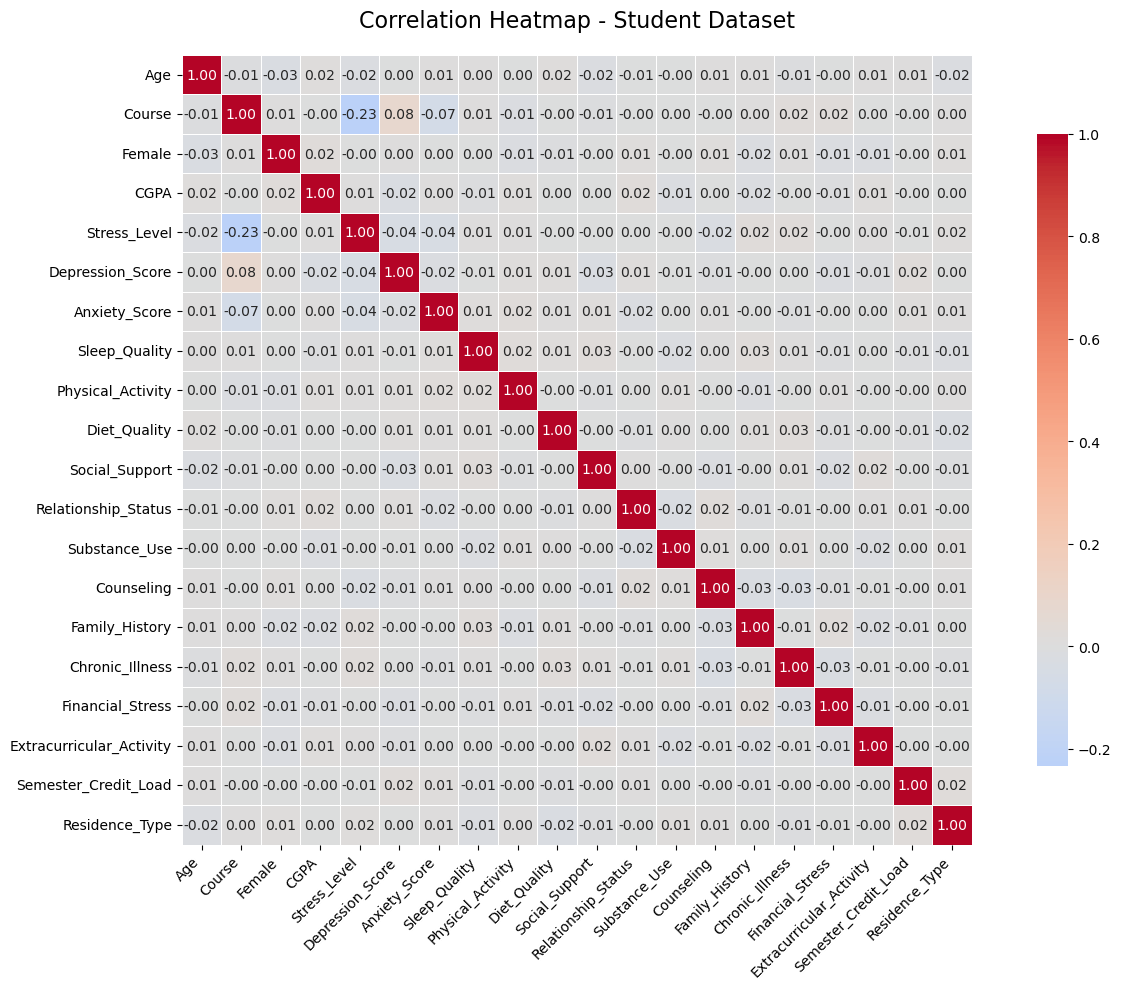

In [23]:
plt.figure(figsize=(14, 10))

# Create correlation matrix
corr = df_clean.corr()

# Heatmap with labels
sns.heatmap(
    corr,
    annot=True,           # Show correlation values
    fmt=".2f",            # 2 decimal places
    cmap="coolwarm",      # Nice color scale (blue = negative, red = positive)
    center=0,             # Center the colormap at 0
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)

plt.title("Correlation Heatmap - Student Dataset", fontsize=16, pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [24]:
def feature_correlation(feature):
    # Features and target
    features = df_clean.drop(columns=[feature]).columns
    results = []
    
    for col in features:
        # Pearson
        pearson_corr, pearson_p = pearsonr(df_clean[col], df_clean[feature])
        
        # Spearman (recommended for ordinal target)
        spearman_corr, spearman_p = spearmanr(df_clean[col], df_clean[feature])
        
        results.append({
            "Feature": col,
            "Pearson_Corr": round(pearson_corr, 4),
            "Pearson_p_value": round(pearson_p, 4),
            "Spearman_Corr": round(spearman_corr, 4),
            "Spearman_p_value": round(spearman_p, 4),
            "Significant (p<0.05)": "Yes" if spearman_p < 0.05 else "No"
        })
    
    # Create DataFrame and sort by absolute Spearman correlation
    corr_df = pd.DataFrame(results)
    corr_df["Abs_Spearman"] = corr_df["Spearman_Corr"].abs()
    corr_df = corr_df.sort_values("Abs_Spearman", ascending=False).drop(columns="Abs_Spearman")
    
    # Display the result
    return corr_df

In [25]:
#'Stress_Level', 'Depression_Score','Anxiety_Score'
SL = feature_correlation('Stress_Level')
SL

,Feature,Pearson_Corr,Pearson_p_value,Spearman_Corr,Spearman_p_value,Significant (p<0.05)
1,Course,-0.2333,0.0000,-0.2610,0.0000,Yes
4,Depression_Score,-0.0436,0.0003,-0.0412,0.0006,Yes
5,Anxiety_Score,-0.0365,0.0022,-0.0371,0.0019,Yes
0,Age,-0.0196,0.1015,-0.0251,0.0356,Yes
12,Counseling,-0.0229,0.0554,-0.0217,0.0695,No
13,Family_History,0.0197,0.0994,0.0201,0.0931,No
14,Chronic_Illness,0.0181,0.1311,0.0184,0.1239,No
18,Residence_Type,0.0159,0.1849,0.0150,0.2099,No
17,Semester_Credit_Load,-0.0057,0.6346,-0.0057,0.6347,No
7,Physical_Activity,0.0062,0.6020,0.0056,0.6389,No


In [26]:
#'Stress_Level', 'Depression_Score','Anxiety_Score'
DL = feature_correlation('Depression_Score')
DL

,Feature,Pearson_Corr,Pearson_p_value,Spearman_Corr,Spearman_p_value,Significant (p<0.05)
1,Course,0.0818,0.0000,0.0943,0.0000,Yes
4,Stress_Level,-0.0436,0.0003,-0.0412,0.0006,Yes
9,Social_Support,-0.0251,0.0360,-0.0261,0.0293,Yes
3,CGPA,-0.0223,0.0619,-0.0244,0.0410,Yes
17,Semester_Credit_Load,0.0231,0.0530,0.0234,0.0500,No
5,Anxiety_Score,-0.0173,0.1488,-0.0176,0.1417,No
15,Financial_Stress,-0.0122,0.3067,-0.0126,0.2937,No
11,Substance_Use,-0.0054,0.6494,-0.0112,0.3506,No
7,Physical_Activity,0.0113,0.3464,0.0105,0.3794,No
8,Diet_Quality,0.0097,0.4180,0.0089,0.4565,No


In [27]:
#'Stress_Level', 'Depression_Score','Anxiety_Score'
AS = feature_correlation('Anxiety_Score')
AS

,Feature,Pearson_Corr,Pearson_p_value,Spearman_Corr,Spearman_p_value,Significant (p<0.05)
1,Course,-0.0730,0.0000,-0.0515,0.0000,Yes
4,Stress_Level,-0.0365,0.0022,-0.0371,0.0019,Yes
7,Physical_Activity,0.0232,0.0521,0.0247,0.0390,Yes
5,Depression_Score,-0.0173,0.1488,-0.0176,0.1417,No
10,Relationship_Status,-0.0172,0.1494,-0.0166,0.1639,No
6,Sleep_Quality,0.0123,0.3027,0.0122,0.3068,No
17,Semester_Credit_Load,0.0121,0.3122,0.0115,0.3383,No
9,Social_Support,0.0119,0.3217,0.0114,0.3391,No
0,Age,0.0075,0.5307,0.0096,0.4199,No
14,Chronic_Illness,-0.0093,0.4389,-0.0094,0.4322,No


In [28]:
df_clean.drop(columns= ['Counseling', 'Semester_Credit_Load'], inplace= True)

In [29]:
df_clean.head()

,Age,Course,Female,CGPA,Stress_Level,Depression_Score,Anxiety_Score,Sleep_Quality,Physical_Activity,Diet_Quality,Social_Support,Relationship_Status,Substance_Use,Family_History,Chronic_Illness,Financial_Stress,Extracurricular_Activity,Residence_Type
0,25,5,0,3.56,3,3,2,2,1,2,1,2,2,0,0,2,1,0
1,24,2,1,2.44,0,3,0,1,0,1,0,0,1,0,0,3,0,0
2,19,4,1,3.74,4,0,3,2,0,1,1,1,2,0,0,4,2,0
4,18,4,0,3.40,3,3,4,2,0,1,2,2,2,0,1,0,2,0
5,21,0,1,3.35,2,4,3,2,1,2,2,0,2,0,0,5,1,1


In [30]:
import os

df_clean.to_csv("../KG_Student_Artifact/KG_Student_Cleaned.csv", index=False)

print("Saved successfully!")

Saved successfully!


In [31]:
print(df.groupby("Course")["Stress_Level"].agg(["mean", "std", "count"]).round(2))

                  mean   std  count
Course                             
Business          2.11  1.58    717
Computer Science  2.05  1.57   1028
Engineering       2.10  1.56   1072
Law               2.12  1.61   1385
Medical           3.21  1.48   2105
Others            2.06  1.61    715


In [32]:
print(df.groupby("Course")["Anxiety_Score"].agg(["mean", "std", "count"]).round(2))

                  mean   std  count
Course                             
Business          2.04  1.58    717
Computer Science  2.05  1.56   1028
Engineering       2.07  1.58   1072
Law               3.23  1.45   1385
Medical           2.08  1.61   2105
Others            2.12  1.54    715


In [33]:
print(df.groupby("Course")["Depression_Score"].agg(["mean", "std", "count"]).round(2))

                  mean   std  count
Course                             
Business          2.10  1.58    717
Computer Science  3.30  1.47   1028
Engineering       2.09  1.56   1072
Law               2.10  1.57   1385
Medical           2.04  1.59   2105
Others            2.07  1.61    715
